### Some stock market testing with Yahoo-Finance and RNN

In [38]:
# this code originally from here:
# https://www.geeksforgeeks.org/machine-learning/time-series-forecasting-using-recurrent-neural-networks-rnn-in-tensorflow/

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# pip install yfinance
import yfinance as yf
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN

This module allows downloading finance data from Yahoo. You can change the company by changing the ticker.

In [40]:
# ticker is the Yahoo's abbreviation of the company (whose stocks we inspect)
# to see which ticker is which company, try: https://finance.yahoo.com/lookup/
# try also NVDA, TTWO and AMD
# results are quite different from reach other
ticker = "AVGO"
data = yf.download(ticker, start="2021-01-01", end="2026-11-09")
data = data['Close'].values.reshape(-1, 1)

[*********************100%***********************]  1 of 1 completed


Scaling required for RNN

In [41]:
# scale the values
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

X/y, train/test etc. splits

In [42]:
# helper function to create X/y -split automatically
def create_dataset(data, time_step=60):
    X, y = [], []
    for i in range(len(data) - time_step - 1):
        X.append(data[i:(i + time_step), 0])
        y.append(data[i + time_step, 0])
    return np.array(X), np.array(y)

X, y = create_dataset(scaled_data)
X = X.reshape(X.shape[0], X.shape[1], 1)

In [43]:
# train_test -split
train_size = int(len(X) * 0.8)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

Create neural network

In [44]:
# create neurlan network, two connected SimpleRNN's
model = Sequential()
model.add(SimpleRNN(units=50, return_sequences=True, input_shape=(X_train.shape[1], 1)))
model.add(SimpleRNN(units=50, return_sequences=False))
model.add(Dense(units=1))
model.compile(optimizer='adam', loss='mean_squared_error')

c:\Users\tuomas.valtanen\deeplearning2026lectures\DeepLearningAutumn2026\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Train model and create predictions

In [45]:
# train model
model.fit(X_train, y_train, epochs=20, batch_size=64)

# create predictions
predictions = model.predict(X_test)
predictions = scaler.inverse_transform(predictions)

Epoch 1/20


18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0161
Epoch 2/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0014
Epoch 3/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 6.5359e-04
Epoch 4/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 4.4898e-04
Epoch 5/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 3.8156e-04
Epoch 6/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 3.3180e-04
Epoch 7/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 3.2729e-04
Epoch 8/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 3.0433e-04
Epoch 9/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 2.6075e-04
Epoch 10/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 2.3895e-04
Epoch 11/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 2.4847e-04
Epoch 12/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 2.0197e-04
Epoch 13/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.9046e-04
Epoch 14/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.8750e-04
Epoch 15/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/st

In [46]:
# error metrics
y_test_unscaled = scaler.inverse_transform(y_test.reshape(-1, 1))

mse = mean_squared_error(y_test_unscaled, predictions)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test_unscaled, predictions)

print(f"Unscaled Mean Squared Error (MSE): {mse}")
print(f"Unscaled Root Mean Squared Error (RMSE): {rmse}")
print(f"Unscaled Mean Absolute Error (MAE): {mae}")

Unscaled Mean Squared Error (MSE): 208.72794305737273
Unscaled Root Mean Squared Error (RMSE): 14.447419944660457
Unscaled Mean Absolute Error (MAE): 11.12681438905973


### Finally, plot the PREDICTION vs TEST signal

NOTE: Anything "predicted" / extrapolated after this test signal => prediction quality tends to decrease (see other forecasting examples)

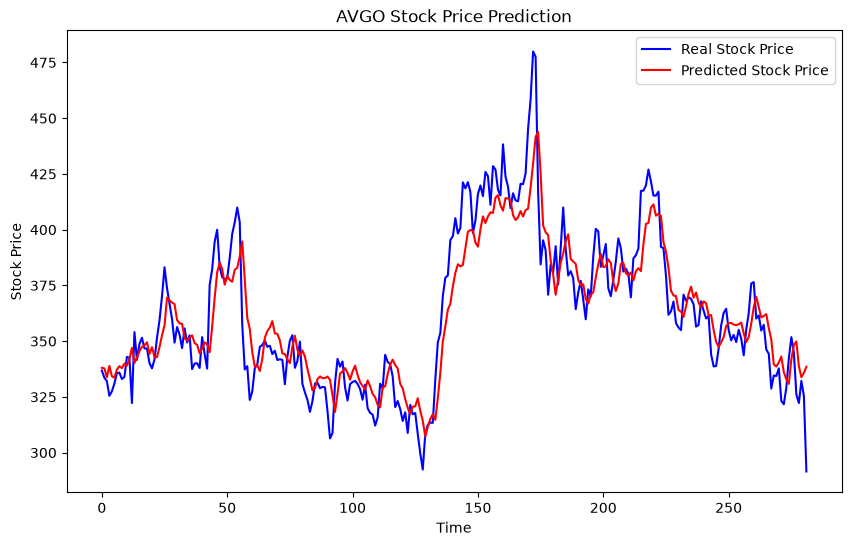

In [47]:
plt.figure(figsize=(10,6))
plt.plot(scaler.inverse_transform(y_test.reshape(-1, 1)), color='blue', label='Real Stock Price')
plt.plot(predictions, color='red', label='Predicted Stock Price')
plt.title(f'{ticker} Stock Price Prediction')
plt.xlabel('Time')
plt.ylabel('Stock Price')
plt.legend()
plt.show()

### Remember, if you use forecasting into tomorrow's data, you never have any comparison if it's good or not

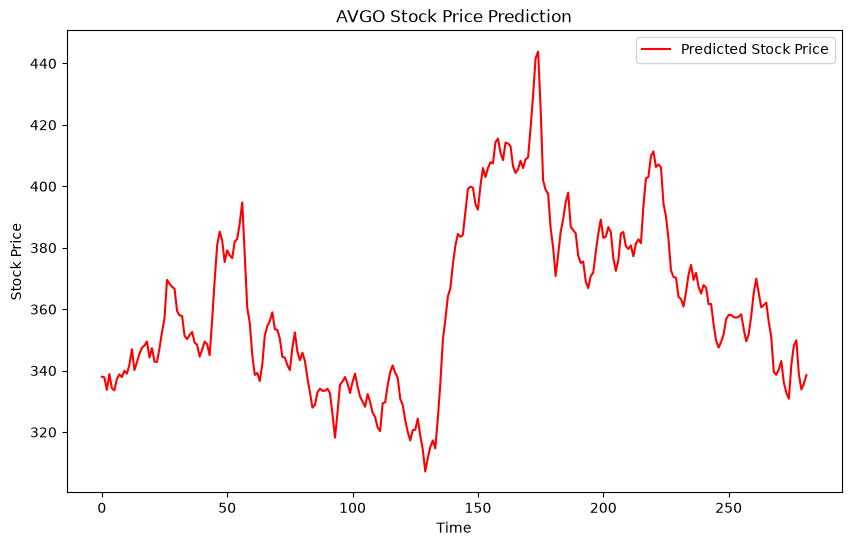

In [48]:
plt.figure(figsize=(10,6))
#plt.plot(scaler.inverse_transform(y_test.reshape(-1, 1)), color='blue', label='Real Stock Price')
plt.plot(predictions, color='red', label='Predicted Stock Price')
plt.title(f'{ticker} Stock Price Prediction')
plt.xlabel('Time')
plt.ylabel('Stock Price')
plt.legend()
plt.show()

# so is this signal good or not? in real-life real-time data, you'll never know 